# SMS Spam Detector - Entrega final
Proyecto final - Sistemas Inteligentes - Universidad de Ibagué

Nombres de los integrantes:
- Christian Cuellar
- Daniel Reyes
- Javier Galeano Zapata

Cambios respecto a la Fase III:
- Se corrigió la limpieza del texto (el token `ltgt`).
- Se quitan los mensajes duplicados **antes** de dividir los datos, y esa es ahora la evaluación principal.
- El número de épocas del MLP se escoge con un conjunto de validación y se prueban pesos de clase.
- Se revisan los mensajes mal clasificados y se escoge el modelo final del agente.

In [1]:
import re
import string
import csv
import html

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, make_scorer
)

RANDOM_STATE = 42

## Dataset

In [2]:
from google.colab import files
uploaded = files.upload()

In [3]:
df = pd.read_csv("SMSSpamCollection", sep="\t", header=None, names=["label", "text"], quoting=csv.QUOTE_NONE)
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df["label"].value_counts()

label
ham     4827
spam     747
Name: count, dtype: int64

## Análisis exploratorio

In [5]:
df.isnull().sum()

label    0
text     0
dtype: int64

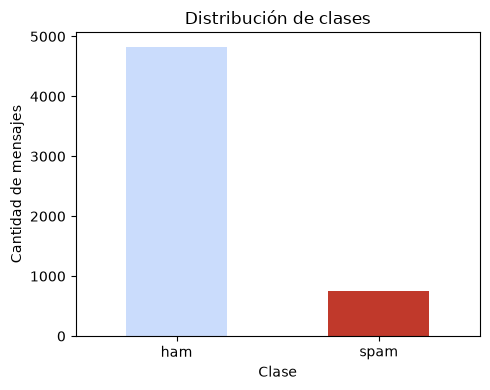

In [6]:
conteo = df["label"].value_counts()

plt.figure(figsize=(5, 4))
conteo.plot(kind="bar", color=["#CADCFC", "#C0392B"])
plt.title("Distribución de clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad de mensajes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

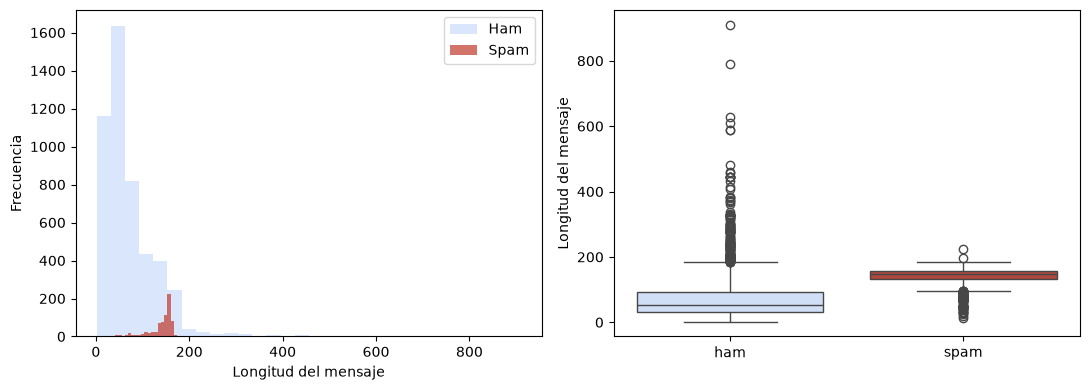

label
ham      71.471929
spam    138.676037
Name: length, dtype: float64

In [7]:
df["length"] = df["text"].apply(len)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df[df.label == "ham"]["length"], bins=30, alpha=0.7, label="Ham", color="#CADCFC")
axes[0].hist(df[df.label == "spam"]["length"], bins=30, alpha=0.7, label="Spam", color="#C0392B")
axes[0].set_xlabel("Longitud del mensaje")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

sns.boxplot(x="label", y="length", data=df, hue="label", palette={"ham": "#CADCFC", "spam": "#C0392B"}, legend=False, ax=axes[1])
axes[1].set_xlabel("")
axes[1].set_ylabel("Longitud del mensaje")

plt.tight_layout()
plt.show()

df.groupby("label")["length"].mean()

## Preprocesamiento

En la Fase III la palabra con más peso hacia ham era `ltgt`, que no es una palabra real. Sale del código `&lt;#&gt;`, que el dataset usa para esconder números en algunos mensajes normales. Como solo aparece en ham, el modelo aprendía a usarlo. Ahora convertimos los códigos HTML y quitamos ese marcador antes de limpiar.

In [8]:
print("Mensajes con &lt;#&gt;:", df["text"].str.contains("&lt;#&gt;", regex=False).sum())
df[df["text"].str.contains("&lt;#&gt;", regex=False)]["label"].value_counts()

Mensajes con &lt;#&gt;: 214


label
ham    214
Name: count, dtype: int64

In [9]:
def clean_text(text):
    text = text.replace("&lt;#&gt;", " ")
    text = html.unescape(text)
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " url ", text)
    text = re.sub(r"\d+", " num ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head()

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in num a wkly comp to win fa cup fi...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


## Mensajes duplicados

En la Fase III vimos que hay mensajes repetidos. Si una copia queda en train y otra en test, el modelo ya vio ese mensaje y el resultado sale mejor de lo que es. Por eso ahora quitamos los duplicados antes de dividir.

In [10]:
X_tr_dup, X_te_dup, _, _ = train_test_split(
    df["clean_text"], df["label"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=df["label"]
)
print("Duplicados después de limpiar:", df["clean_text"].duplicated().sum())
print("Con duplicados, mensajes de test que también están en train:", X_te_dup.isin(set(X_tr_dup)).sum(), "de", len(X_te_dup))

df_final = df.drop_duplicates("clean_text").reset_index(drop=True)
print("Mensajes sin duplicados:", len(df_final))
df_final["label"].value_counts()

Duplicados después de limpiar: 472
Con duplicados, mensajes de test que también están en train: 154 de 1115
Mensajes sin duplicados: 5102


label
ham     4501
spam     601
Name: count, dtype: int64

## División de datos

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    df_final["clean_text"], df_final["label"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=df_final["label"]
)

print("Train:", len(X_train), "Test:", len(X_test))
print("Spam en test:", (y_test == "spam").sum())
print("Mensajes de test que están en train:", X_test.isin(set(X_train)).sum())

Train: 4081 Test: 1021
Spam en test: 120
Mensajes de test que están en train: 0


## Modelo base

In [12]:
pipe_base = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=10, random_state=RANDOM_STATE)),
])

pipe_base.fit(X_train, y_train)
y_pred_base = pipe_base.predict(X_test)

print("accuracy:", accuracy_score(y_test, y_pred_base))
print("precision:", precision_score(y_test, y_pred_base, pos_label="spam"))
print("recall:", recall_score(y_test, y_pred_base, pos_label="spam"))
print("f1:", f1_score(y_test, y_pred_base, pos_label="spam"))

accuracy: 0.9755142017629774
precision: 0.8625954198473282
recall: 0.9416666666666667
f1: 0.900398406374502


## Ajuste de hiperparámetros (sin duplicados)

In [13]:
f1_spam = make_scorer(f1_score, pos_label="spam")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2, 3],
    "clf__C": [0.1, 1, 10, 50],
}

grid = GridSearchCV(pipe, param_grid, scoring=f1_spam, cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'clf__C': 50, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 1)}
0.9172043924307527


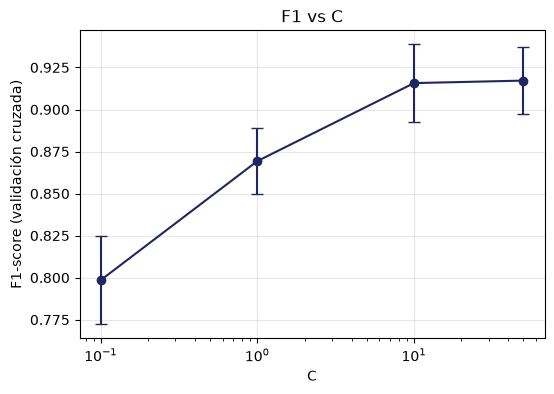

In [14]:
best_ngram = grid.best_params_["tfidf__ngram_range"]
best_min_df = grid.best_params_["tfidf__min_df"]
best_C = grid.best_params_["clf__C"]
c_values = [0.1, 1, 10, 50]

pipe_c = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=best_ngram, min_df=best_min_df)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
])

grid_c = GridSearchCV(pipe_c, {"clf__C": c_values}, scoring=f1_spam, cv=cv, n_jobs=-1)
grid_c.fit(X_train, y_train)

medias = grid_c.cv_results_["mean_test_score"]
desviaciones = grid_c.cv_results_["std_test_score"]

plt.figure(figsize=(6, 4))
plt.errorbar(c_values, medias, yerr=desviaciones, fmt="-o", color="#1E2761", capsize=4)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("F1-score (validación cruzada)")
plt.title("F1 vs C")
plt.grid(True, alpha=0.3)
plt.show()

## Regresión Logística final

In [15]:
mejor_modelo = grid.best_estimator_
y_pred = mejor_modelo.predict(X_test)
y_proba = mejor_modelo.predict_proba(X_test)[:, 1]

exactitud = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="spam")
sensibilidad = recall_score(y_test, y_pred, pos_label="spam")
f1 = f1_score(y_test, y_pred, pos_label="spam")

print("accuracy:", exactitud)
print("precision:", precision)
print("recall:", sensibilidad)
print("f1:", f1)

accuracy: 0.9833496571988247
precision: 0.9327731092436975
recall: 0.925
f1: 0.9288702928870293


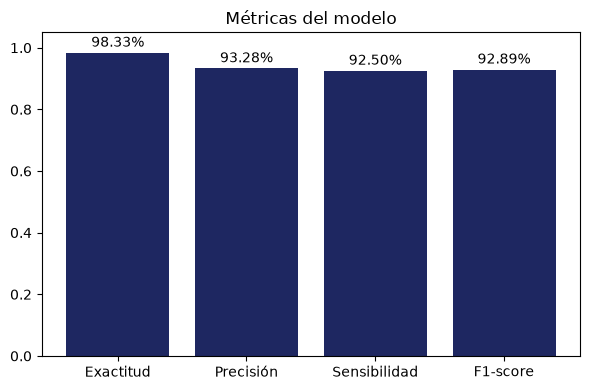

In [16]:
metricas = {
    "Exactitud": exactitud,
    "Precisión": precision,
    "Sensibilidad": sensibilidad,
    "F1-score": f1,
}

plt.figure(figsize=(6, 4))
plt.bar(metricas.keys(), metricas.values(), color="#1E2761")
plt.ylim(0, 1.05)
for i, v in enumerate(metricas.values()):
    plt.text(i, v + 0.02, f"{v*100:.2f}%", ha="center")
plt.title("Métricas del modelo")
plt.tight_layout()
plt.show()

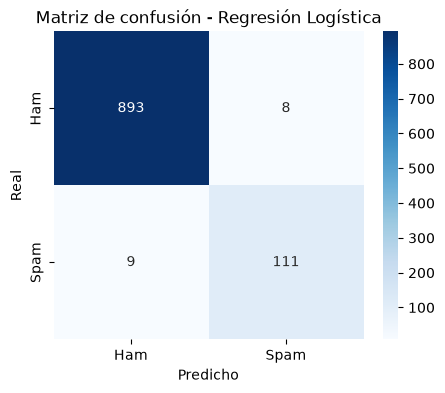

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.title("Matriz de confusión - Regresión Logística")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

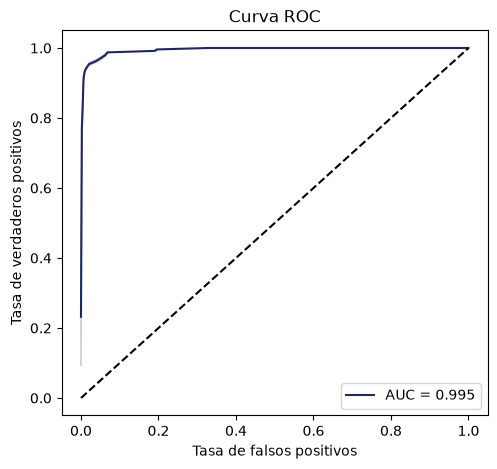

In [18]:
y_test_bin = (y_test == "spam").astype(int)
fpr, tpr, _ = roc_curve(y_test_bin, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5.5, 5))
sns.lineplot(x=fpr, y=tpr, color="#1E2761", label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC")
plt.legend()
plt.show()

## Comparación con otros modelos

In [19]:
modelos = {
    "Regresión Logística": mejor_modelo,
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=best_ngram, min_df=best_min_df)),
        ("clf", MultinomialNB()),
    ]),
    "SVM Lineal": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=best_ngram, min_df=best_min_df)),
        ("clf", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=best_ngram, min_df=best_min_df)),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

resultados = []
for nombre, modelo in modelos.items():
    if nombre != "Regresión Logística":
        modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    cm_m = confusion_matrix(y_test, pred, labels=["ham", "spam"])
    resultados.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, pos_label="spam"),
        "recall": recall_score(y_test, pred, pos_label="spam"),
        "f1": f1_score(y_test, pred, pos_label="spam"),
        "FP": cm_m[0, 1],
        "FN": cm_m[1, 0],
    })

tabla = pd.DataFrame(resultados)
tabla

,modelo,accuracy,precision,recall,f1,FP,FN
0,Regresión Logística,0.983350,0.932773,0.925000,0.928870,8,9
1,Naive Bayes,0.976494,0.980000,0.816667,0.890909,2,22
2,SVM Lineal,0.981391,0.910569,0.933333,0.921811,11,8
3,Random Forest,0.982370,0.932203,0.916667,0.924370,8,10


## Interpretabilidad

In [20]:
vectorizador = mejor_modelo.named_steps["tfidf"]
clasificador = mejor_modelo.named_steps["clf"]

terminos = np.array(vectorizador.get_feature_names_out())
coeficientes = clasificador.coef_[0]

orden = np.argsort(coeficientes)
top_spam = list(zip(terminos[orden[-15:]], coeficientes[orden[-15:]]))[::-1]
top_ham = list(zip(terminos[orden[:15]], coeficientes[orden[:15]]))

print("ltgt sigue en el vocabulario:", "ltgt" in terminos)
print()
for termino, coef in top_spam:
    print(termino, coef)

ltgt sigue en el vocabulario: False

url 13.411080151726601
won 9.678718276065135
mobile 9.231766044532872
txt 9.141542952176948
num 9.137000891156076
sale 8.897715837253863
choose 8.132607424165553
sexy 8.057793781746836
chat 7.902144186845968
service 7.831521404696157
pmin 7.693836590737189
games 7.359478207505954
claim 6.945538105639167
welcome 6.912621095810316
reply 6.911703451229213


In [21]:
for termino, coef in top_ham:
    print(termino, coef)

face -5.308882315895024
ill -5.130487890902461
lovable -4.982064582862261
home -4.9362065114553175
later -4.017671713439488
hey -3.9452912585016255
thats -3.9241580579360047
ard -3.789370951635634
liked -3.7849779466713307
sir -3.7822914177134446
didn -3.6815182662218775
yesterday -3.6033783664870764
lor -3.5271854075475657
funny -3.490691737279798
im -3.463715119603422


## Red neuronal (MLP)

Separamos un 20% del entrenamiento como validación. Entrenamos 60 épocas y miramos el loss de validación para escoger cuántas épocas usar. El test no se usa para esto.

In [22]:
X_tr_nn, X_val_nn, y_tr_nn, y_val_nn = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train
)

tfidf_val = TfidfVectorizer(stop_words="english", ngram_range=best_ngram, min_df=best_min_df)
X_a = tfidf_val.fit_transform(X_tr_nn).toarray()
X_v = tfidf_val.transform(X_val_nn).toarray()
y_a = (y_tr_nn == "spam").astype(int).to_numpy().reshape(-1, 1)
y_v = (y_val_nn == "spam").astype(int).to_numpy()

print(X_a.shape, X_v.shape)

(3264, 1548) (817, 1548)


In [23]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_deriv(x):
    return sigmoid(x) * (1 - sigmoid(x))


def entrenar_mlp(X, y, epochs=30, lr=0.1, batch_size=64, hidden_size=64, peso_spam=1.0, X_val=None, y_val=None):
    np.random.seed(42)
    W1 = np.random.randn(X.shape[1], hidden_size) * 0.01
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, 1) * 0.01
    b2 = np.zeros((1, 1))
    historial = []

    for epoch in range(epochs):
        for i in range(0, X.shape[0], batch_size):
            X_batch = X[i:i+batch_size]
            y_batch = y[i:i+batch_size]

            Z1 = np.dot(X_batch, W1) + b1
            A1 = sigmoid(Z1)
            Z2 = np.dot(A1, W2) + b2
            A2 = sigmoid(Z2)

            pesos = np.where(y_batch == 1, peso_spam, 1.0)
            dZ2 = (A2 - y_batch) * pesos
            dW2 = np.dot(A1.T, dZ2)
            db2 = np.sum(dZ2, axis=0, keepdims=True)

            dA1 = np.dot(dZ2, W2.T) * sigmoid_deriv(Z1)
            dW1 = np.dot(X_batch.T, dA1)
            db1 = np.sum(dA1, axis=0, keepdims=True)

            W2 -= lr * dW2
            b2 -= lr * db2
            W1 -= lr * dW1
            b1 -= lr * db1

        if X_val is not None:
            A2_tr = sigmoid(np.dot(sigmoid(np.dot(X, W1) + b1), W2) + b2)
            loss_tr = -np.mean(y * np.log(A2_tr + 1e-9) + (1 - y) * np.log(1 - A2_tr + 1e-9))
            A2_val = sigmoid(np.dot(sigmoid(np.dot(X_val, W1) + b1), W2) + b2)[:, 0]
            loss_val = -np.mean(y_val * np.log(A2_val + 1e-9) + (1 - y_val) * np.log(1 - A2_val + 1e-9))
            f1_val = f1_score(y_val, (A2_val >= 0.5).astype(int))
            historial.append([epoch + 1, loss_tr, loss_val, f1_val])

    return W1, b1, W2, b2, historial


def predecir_mlp(X, W1, b1, W2, b2):
    A1 = sigmoid(np.dot(X, W1) + b1)
    A2 = sigmoid(np.dot(A1, W2) + b2)
    return np.where(A2[:, 0] >= 0.5, "spam", "ham")

In [24]:
_, _, _, _, hist = entrenar_mlp(X_a, y_a, epochs=60, X_val=X_v, y_val=y_v)
hist = pd.DataFrame(hist, columns=["epoca", "loss_train", "loss_val", "f1_val"])

mejor_epoca = int(hist.loc[hist["loss_val"].idxmin(), "epoca"])
print("Época con menor loss de validación:", mejor_epoca)
hist.iloc[[0, 4, 9, 14, 19, 24, 29, 39, 49, 59]].round(4)

Época con menor loss de validación: 22


,epoca,loss_train,loss_val,f1_val
0,1,0.1911,0.1926,0.5915
4,5,0.1013,0.1110,0.8197
9,10,0.0604,0.0808,0.8840
14,15,0.0396,0.0704,0.8901
19,20,0.0280,0.0678,0.9121
24,25,0.0208,0.0680,0.9171
29,30,0.0161,0.0689,0.9171
39,40,0.0104,0.0701,0.9121
49,50,0.0070,0.0700,0.9071
59,60,0.0051,0.0697,0.9130


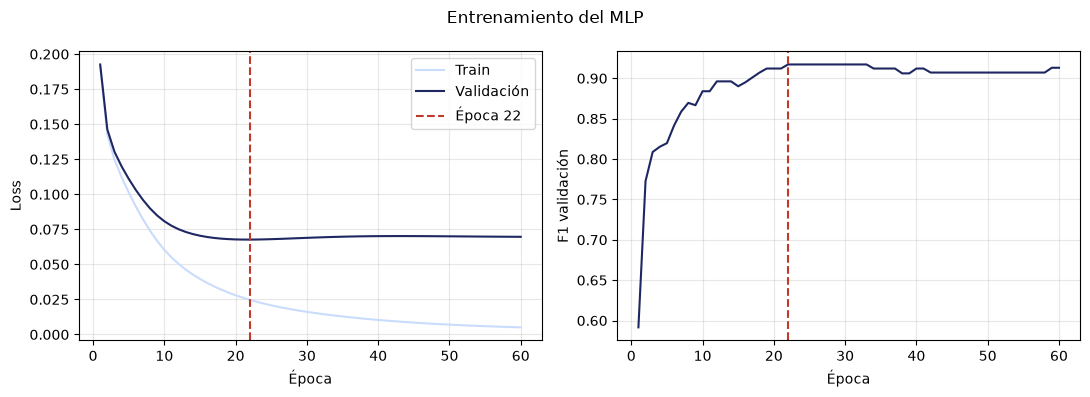

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(hist["epoca"], hist["loss_train"], label="Train", color="#CADCFC")
axes[0].plot(hist["epoca"], hist["loss_val"], label="Validación", color="#1E2761")
axes[0].axvline(mejor_epoca, color="#C0392B", linestyle="--", label=f"Época {mejor_epoca}")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist["epoca"], hist["f1_val"], color="#1E2761")
axes[1].axvline(mejor_epoca, color="#C0392B", linestyle="--")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("F1 validación")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Entrenamiento del MLP")
plt.tight_layout()
plt.show()

### Pesos de clase en el MLP

La Regresión Logística usa `class_weight="balanced"` y el MLP no. Probamos darle más peso a los errores en spam (ham/spam en train) y comparamos en validación.

In [26]:
peso = (y_a == 0).sum() / (y_a == 1).sum()
print("Peso para spam:", peso)

_, _, _, _, hist_w = entrenar_mlp(X_a, y_a, epochs=60, peso_spam=peso, X_val=X_v, y_val=y_v)
hist_w = pd.DataFrame(hist_w, columns=["epoca", "loss_train", "loss_val", "f1_val"])

print("Sin pesos - F1 validación en la época", mejor_epoca, ":", round(hist.loc[mejor_epoca - 1, "f1_val"], 4))
print("Con pesos - mejor F1 validación:", round(hist_w["f1_val"].max(), 4), "en la época", int(hist_w.loc[hist_w["f1_val"].idxmax(), "epoca"]))
print("Con pesos - loss de validación en las primeras 4 épocas:", hist_w["loss_val"].head(4).round(3).tolist())

Peso para spam: 7.477922077922078
Sin pesos - F1 validación en la época 22 : 0.9171
Con pesos - mejor F1 validación: 0.918 en la época 30
Con pesos - loss de validación en las primeras 4 épocas: [2.989, 2.963, 2.887, 0.251]


Con pesos el F1 de validación casi no cambia (0.918 contra 0.917) y las primeras épocas son inestables (el loss de validación empieza cerca de 3 porque el learning rate queda muy alto para esos pesos). Por eso el MLP final se queda sin pesos y con las épocas escogidas arriba.

In [27]:
tfidf_nn = TfidfVectorizer(stop_words="english", ngram_range=best_ngram, min_df=best_min_df)
X_train_nn = tfidf_nn.fit_transform(X_train).toarray()
X_test_nn = tfidf_nn.transform(X_test).toarray()
y_train_nn = (y_train == "spam").astype(int).to_numpy().reshape(-1, 1)

W1, b1, W2, b2, _ = entrenar_mlp(X_train_nn, y_train_nn, epochs=mejor_epoca)
y_pred_nn = predecir_mlp(X_test_nn, W1, b1, W2, b2)

exactitud_nn = accuracy_score(y_test, y_pred_nn)
precision_nn = precision_score(y_test, y_pred_nn, pos_label="spam")
sensibilidad_nn = recall_score(y_test, y_pred_nn, pos_label="spam")
f1_nn = f1_score(y_test, y_pred_nn, pos_label="spam")

print(X_train_nn.shape)
print("accuracy:", exactitud_nn)
print("precision:", precision_nn)
print("recall:", sensibilidad_nn)
print("f1:", f1_nn)

(4081, 1819)
accuracy: 0.9843290891283056
precision: 0.9482758620689655
recall: 0.9166666666666666
f1: 0.9322033898305084


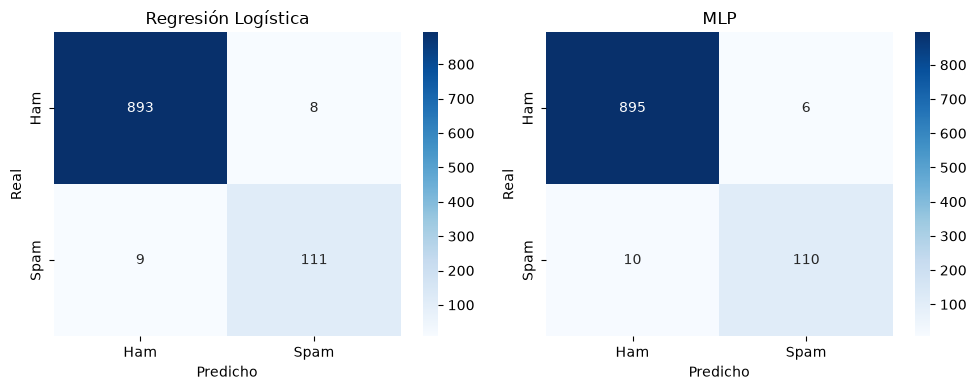

In [28]:
cm_nn = confusion_matrix(y_test, y_pred_nn, labels=["ham", "spam"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"], ax=axes[0])
axes[0].set_title("Regresión Logística")
axes[0].set_xlabel("Predicho")
axes[0].set_ylabel("Real")
sns.heatmap(cm_nn, annot=True, fmt="d", cmap="Blues", xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"], ax=axes[1])
axes[1].set_title("MLP")
axes[1].set_xlabel("Predicho")
axes[1].set_ylabel("Real")
plt.tight_layout()
plt.show()

## Regresión Logística vs MLP

In [29]:
def probar_mlp(textos_train, y_train_, textos_test, epochs):
    tfidf = TfidfVectorizer(stop_words="english", ngram_range=best_ngram, min_df=best_min_df)
    X_a_ = tfidf.fit_transform(textos_train).toarray()
    X_b_ = tfidf.transform(textos_test).toarray()
    y_a_ = (y_train_ == "spam").astype(int).to_numpy().reshape(-1, 1)
    W1_, b1_, W2_, b2_, _ = entrenar_mlp(X_a_, y_a_, epochs=epochs)
    return predecir_mlp(X_b_, W1_, b1_, W2_, b2_)


f1_lr = []
f1_mlp = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_a_cv, X_b_cv = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_a_cv, y_b_cv = y_train.iloc[train_idx], y_train.iloc[val_idx]

    modelo_lr = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=best_ngram, min_df=best_min_df)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=best_C, random_state=RANDOM_STATE)),
    ])
    modelo_lr.fit(X_a_cv, y_a_cv)
    f1_lr.append(f1_score(y_b_cv, modelo_lr.predict(X_b_cv), pos_label="spam"))
    f1_mlp.append(f1_score(y_b_cv, probar_mlp(X_a_cv, y_a_cv, X_b_cv, mejor_epoca), pos_label="spam"))

print("F1 por fold LR: ", np.round(f1_lr, 4))
print("F1 por fold MLP:", np.round(f1_mlp, 4))
print("F1 Regresión Logística:", np.mean(f1_lr), "+-", np.std(f1_lr))
print("F1 MLP:", np.mean(f1_mlp), "+-", np.std(f1_mlp))

F1 por fold LR:  [0.9388 0.9442 0.9005 0.9053 0.8973]
F1 por fold MLP: [0.9538 0.9158 0.911  0.8865 0.8827]
F1 Regresión Logística: 0.9172043924307527 +- 0.020045872129308924
F1 MLP: 0.9099596885321132 +- 0.025519274651062764


In [30]:
comparacion = pd.DataFrame({
    "Regresión Logística": [exactitud, precision, sensibilidad, f1, cm[0, 1], cm[1, 0], np.mean(f1_lr)],
    "MLP": [exactitud_nn, precision_nn, sensibilidad_nn, f1_nn, cm_nn[0, 1], cm_nn[1, 0], np.mean(f1_mlp)],
}, index=["Exactitud", "Precisión", "Sensibilidad", "F1-score", "Falsos positivos", "Falsos negativos", "F1 validación cruzada"])

comparacion.round(4)

,Regresión Logística,MLP
Exactitud,0.9833,0.9843
Precisión,0.9328,0.9483
Sensibilidad,0.9250,0.9167
F1-score,0.9289,0.9322
Falsos positivos,8.0000,6.0000
Falsos negativos,9.0000,10.0000
F1 validación cruzada,0.9172,0.9100


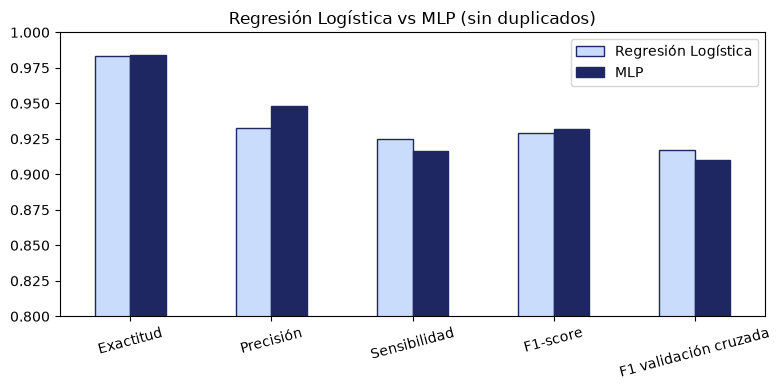

In [31]:
comparacion.loc[["Exactitud", "Precisión", "Sensibilidad", "F1-score", "F1 validación cruzada"]].plot(
    kind="bar", figsize=(8, 4), color=["#CADCFC", "#1E2761"], edgecolor="#1E2761"
)
plt.ylim(0.8, 1.0)
plt.xticks(rotation=15)
plt.title("Regresión Logística vs MLP (sin duplicados)")
plt.tight_layout()
plt.show()

## Revisión de errores

In [32]:
errores = pd.DataFrame({
    "texto": df_final.loc[X_test.index, "text"],
    "real": y_test,
    "lr": y_pred,
    "p_spam_lr": y_proba.round(3),
    "mlp": y_pred_nn,
})

falsos_positivos = errores[(errores["real"] == "ham") & (errores["lr"] == "spam")]
falsos_negativos = errores[(errores["real"] == "spam") & (errores["lr"] == "ham")]

print("Falsos positivos de la Regresión Logística:", len(falsos_positivos))
pd.set_option("display.max_colwidth", 120)
falsos_positivos[["texto", "p_spam_lr", "mlp"]]

Falsos positivos de la Regresión Logística: 8


,texto,p_spam_lr,mlp
3094,Ee msg na poortiyagi odalebeku: Hanumanji 7 name 1-Hanuman 2-Bajarangabali 3-Maruti 4-Pavanaputra 5-Sankatmochan 6-R...,0.983,spam
2264,"Hi, Mobile no. &lt;#&gt; has added you in their contact list on www.fullonsms.com It s a great place to send free ...",0.981,spam
2906,staff.science.nus.edu.sg/~phyhcmk/teaching/pc1323,0.963,spam
4746,K k:) sms chat with me.,0.900,spam
1249,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May",0.872,spam
1613,Glad to see your reply.,0.547,ham
4678,"""HI BABE UAWAKE?FEELLIKW SHIT.JUSTFOUND OUT VIA ALETTER THATMUM GOTMARRIED 4thNOV.BEHIND OURBACKS  FUCKINNICE!SELFI...",0.584,ham
4760,U 2.,0.963,spam


In [33]:
print("Falsos negativos de la Regresión Logística:", len(falsos_negativos))
falsos_negativos[["texto", "p_spam_lr", "mlp"]]

Falsos negativos de la Regresión Logística: 9


,texto,p_spam_lr,mlp
2430,This message is brought to you by GMW Ltd. and is not connected to the,0.186,ham
3944,Block Breaker now comes in deluxe format with new features and great graphics from T-Mobile. Buy for just £5 by repl...,0.483,ham
3143,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,0.007,ham
2666,ROMCAPspam Everyone around should be responding well to your presence since you are so warm and outgoing. You are br...,0.081,ham
3194,LIFE has never been this much fun and great until you came in. You made it truly special for me. I won't forget you!...,0.036,ham
4575,You can donate £2.50 to UNICEF's Asian Tsunami disaster support fund by texting DONATE to 864233. £2.50 will be adde...,0.258,ham
4558,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all...",0.390,ham
1580,"0A$NETWORKS allow companies to bill for SMS, so they are responsible for their ""suppliers"", just as a shop has to gi...",0.104,ham
3906,Missed call alert. These numbers called but left no message. 07008009200,0.043,ham


In [34]:
mal_lr = errores["real"] != errores["lr"]
mal_mlp = errores["real"] != errores["mlp"]
print("Errores de LR:", mal_lr.sum())
print("Errores del MLP:", mal_mlp.sum())
print("Errores en los dos:", (mal_lr & mal_mlp).sum())
print("Longitud promedio de los spam que se escapan:", falsos_negativos["texto"].str.len().mean())
print("Longitud promedio de todo el spam de test:", errores[errores["real"] == "spam"]["texto"].str.len().mean())

Errores de LR: 17
Errores del MLP: 16
Errores en los dos: 15
Longitud promedio de los spam que se escapan: 121.22222222222223
Longitud promedio de todo el spam de test: 135.96666666666667


## Prueba con mensajes nuevos

In [35]:
mensajes_nuevos = [
    ("WINNER!! You have won a 1000 cash prize. Call 09061701461 now to claim", "spam"),
    ("URGENT: your bank account has been suspended. Verify your details at www.secure-bank-login.com", "spam"),
    ("Hey, are we still meeting at the library at 5?", "ham"),
    ("Mom, I will be home late today, don't wait for me for dinner", "ham"),
    ("Congratulations! You have been selected for a free iPhone. Reply YES to get it", "spam"),
    ("Your package could not be delivered. Pay the 1.99 fee here: http://bit.ly/redeliver", "spam"),
    ("FREE ringtones every week! Text TONE to 87021. 150p/msg", "spam"),
    ("Can you send me the notes from today's class?", "ham"),
    ("I'm at the bus stop, see you in 10 minutes", "ham"),
    ("Happy birthday! Hope you have a great day", "ham"),
    ("Your OTP code is 482913. Do not share it with anyone", "ham"),
    ("Don't forget we have the exam on Monday at 8", "ham"),
]

prueba = pd.DataFrame(mensajes_nuevos, columns=["texto", "esperado"])
textos_limpios = prueba["texto"].apply(clean_text)
prueba["p_spam"] = mejor_modelo.predict_proba(textos_limpios)[:, 1].round(4)
prueba["predicho"] = mejor_modelo.predict(textos_limpios)
prueba["mlp"] = predecir_mlp(tfidf_nn.transform(textos_limpios).toarray(), W1, b1, W2, b2)
print("Aciertos LR:", (prueba["predicho"] == prueba["esperado"]).sum(), "de", len(prueba))
print("Aciertos MLP:", (prueba["mlp"] == prueba["esperado"]).sum(), "de", len(prueba))
prueba

Aciertos LR: 12 de 12
Aciertos MLP: 12 de 12


,texto,esperado,p_spam,predicho,mlp
0,WINNER!! You have won a 1000 cash prize. Call 09061701461 now to claim,spam,0.9999,spam,spam
1,URGENT: your bank account has been suspended. Verify your details at www.secure-bank-login.com,spam,0.9648,spam,spam
2,"Hey, are we still meeting at the library at 5?",ham,0.0015,ham,ham
3,"Mom, I will be home late today, don't wait for me for dinner",ham,0.0001,ham,ham
4,Congratulations! You have been selected for a free iPhone. Reply YES to get it,spam,0.6448,spam,spam
5,Your package could not be delivered. Pay the 1.99 fee here: http://bit.ly/redeliver,spam,0.8810,spam,spam
6,FREE ringtones every week! Text TONE to 87021. 150p/msg,spam,0.9985,spam,spam
7,Can you send me the notes from today's class?,ham,0.0411,ham,ham
8,"I'm at the bus stop, see you in 10 minutes",ham,0.0091,ham,ham
9,Happy birthday! Hope you have a great day,ham,0.0003,ham,ham


## Modelo final

Las diferencias entre la Regresión Logística y el MLP son muy pequeñas: en test el MLP saca F1 0.932 y la Regresión Logística 0.929 (un mensaje de diferencia), y en validación cruzada la Regresión Logística saca 0.917 y el MLP 0.910. Además, 15 de los errores son los mismos en los dos modelos. Para el agente escogemos la Regresión Logística porque es más simple, entrena en segundos y se puede ver qué palabras usa para decidir.

In [36]:
import joblib
joblib.dump(mejor_modelo, "spam_model.joblib")

['spam_model.joblib']